In [19]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The notebook runs from the notebooks/ folder, so go up one level to the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = sqlite3.connect(ROOT / "data" / "processed" / "skating.db")


def query(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return pd.read_sql(sql, con)


# Chart style: light grid behind the data, no top/right frame
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.dpi": 110,
})
COLORS = {"M": "#2a78d6", "W": "#eb6834"}   # blue for men, orange for women

In [2]:
perf = query("""
    SELECT s.category, s.segment, p.tes, p.pcs, p.total
    FROM performances p
    JOIN segments s ON p.segment_id = s.id
""")
perf.head()

,category,segment,tes,pcs,total
0,ID,FD,59.11,50.3,109.41
1,ID,FD,60.33,48.3,108.63
2,ID,FD,59.38,46.7,106.08
3,ID,FD,58.67,48.0,105.67
4,ID,FD,59.69,45.9,105.59


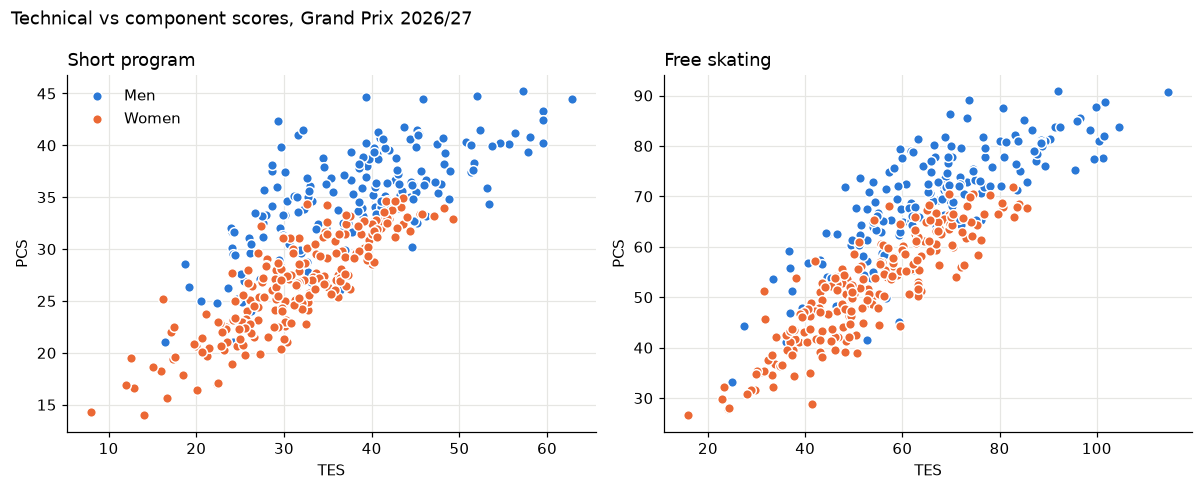

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, segment, title in zip(axes, ["SP", "FS"], ["Short program", "Free skating"]):
    for category, label in [("M", "Men"), ("W", "Women")]:
        d = perf[(perf.segment == segment) & (perf.category == category)]
        ax.scatter(d.tes, d.pcs, s=40, color=COLORS[category], label=label,
                   edgecolor="white", linewidth=1)
    ax.set_title(title, loc="left")
    ax.set_xlabel("TES")
    ax.set_ylabel("PCS")

axes[0].legend(frameon=False)
fig.suptitle("Technical vs component scores, Grand Prix 2026/27", x=0.01, ha="left")
fig.tight_layout()
plt.show()

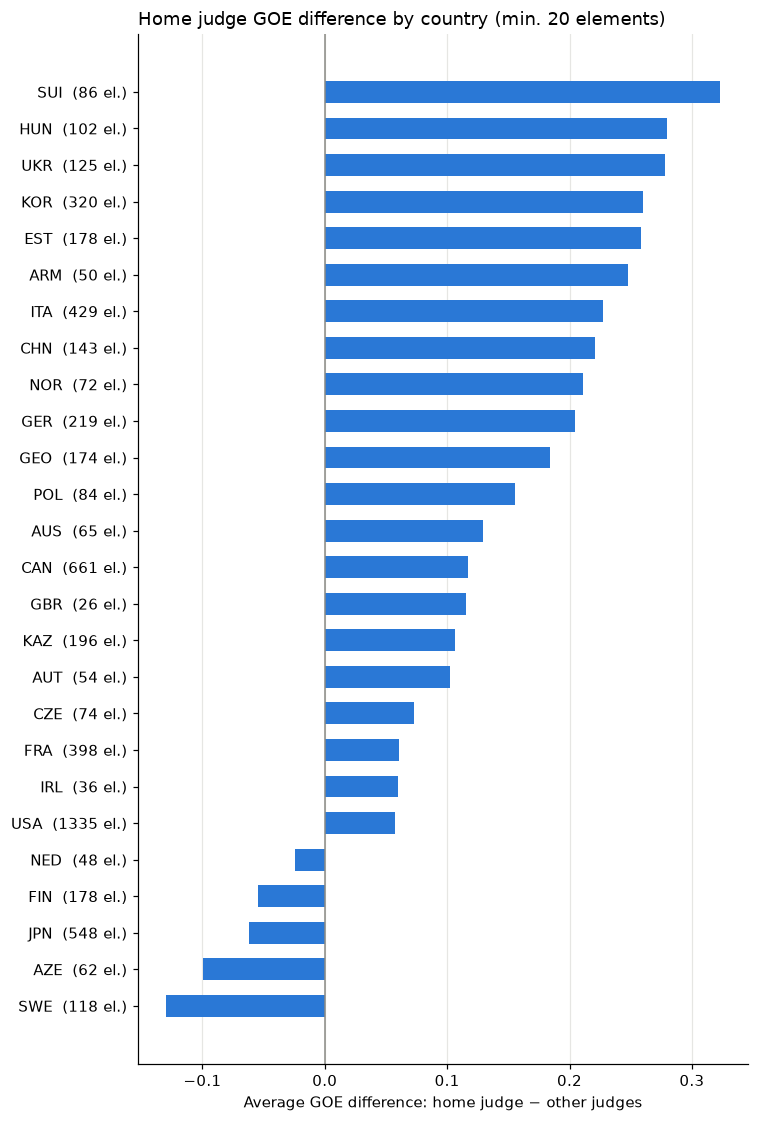

In [4]:
home = query("""
    WITH judged AS (
        SELECT ejs.goe, p.nation AS skater_nation, pa.nation AS judge_nation,
               SUM(ejs.goe)   OVER (PARTITION BY ejs.element_id) AS panel_sum,
               COUNT(ejs.goe) OVER (PARTITION BY ejs.element_id) AS panel_count
        FROM element_judge_scores ejs
        JOIN elements e     ON e.id = ejs.element_id
        JOIN performances p ON p.id = e.performance_id
        JOIN panel pa       ON pa.segment_id = p.segment_id AND pa.judge_number = ejs.judge
        WHERE ejs.goe IS NOT NULL
    )
    SELECT skater_nation AS nation, COUNT(*) AS elements,
           AVG(goe - 1.0 * (panel_sum - goe) / (panel_count - 1)) AS avg_delta
    FROM judged
    WHERE judge_nation = skater_nation
    GROUP BY skater_nation
    HAVING COUNT(*) >= 20
""").sort_values("avg_delta")

labels = [f"{n}  ({e} el.)" for n, e in zip(home.nation, home.elements)]

fig, ax = plt.subplots(figsize=(7, 0.35 * len(home) + 1.2))
ax.barh(labels, home.avg_delta, color=COLORS["M"], height=0.6)
ax.axvline(0, color="#8a8a85", linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Average GOE difference: home judge − other judges")
ax.set_title("Home judge GOE difference by country (min. 20 elements)", loc="left")
fig.tight_layout()
plt.show()

## All four disciplines, GOE in points

Charts using pairs and ice dance, and each judge's GOE converted to points (`element_judge_scores.goe_points`).

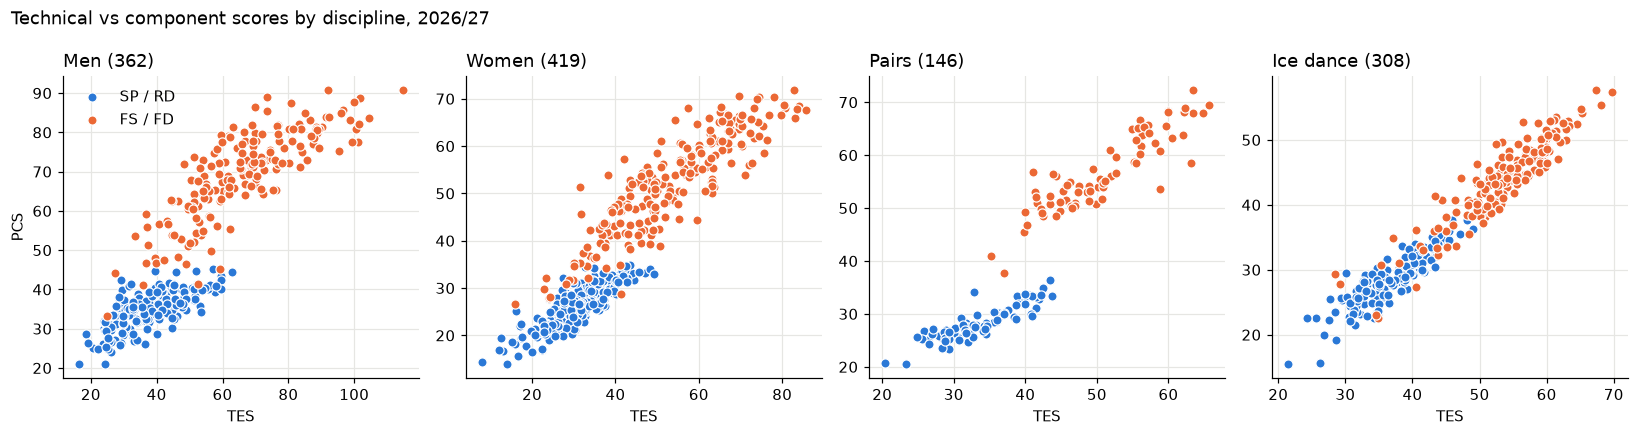

In [5]:
# All four disciplines: TES vs PCS, short segment (SP / RD) vs free segment (FS / FD)
perf = query("""
    SELECT s.category, s.segment, p.tes, p.pcs, p.total
    FROM performances p
    JOIN segments s ON p.segment_id = s.id
""")
perf["part"] = perf.segment.map({"SP": "short", "RD": "short", "FS": "free", "FD": "free"})

DISCIPLINES = [("M", "Men"), ("W", "Women"), ("P", "Pairs"), ("ID", "Ice dance")]
PART_COLORS = {"short": "#2a78d6", "free": "#eb6834"}   # categorical slots 1 and 2

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (category, title) in zip(axes, DISCIPLINES):
    for part, label in [("short", "SP / RD"), ("free", "FS / FD")]:
        d = perf[(perf.category == category) & (perf.part == part)]
        ax.scatter(d.tes, d.pcs, s=36, color=PART_COLORS[part], label=label,
                   edgecolor="white", linewidth=0.8)
    ax.set_title(f"{title} ({(perf.category == category).sum()})", loc="left")
    ax.set_xlabel("TES")
axes[0].set_ylabel("PCS")
axes[0].legend(frameon=False)
fig.suptitle("Technical vs component scores by discipline, 2026/27", x=0.01, ha="left")
fig.tight_layout()
plt.show()

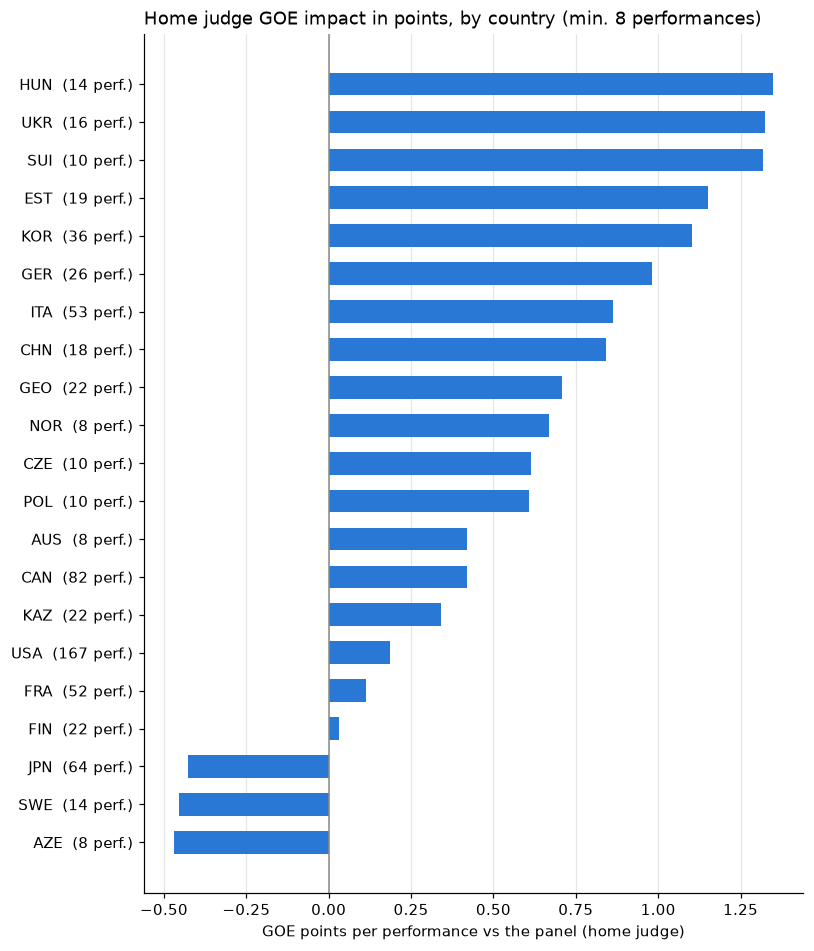

In [6]:
# Home judges in real points: for each performance with a judge of the same nation,
# the points their GOE marks give compared with the panel (judge's points - panel GOE),
# summed over the program's elements
impact = query("""
    WITH per_performance AS (
        SELECT p.id, p.nation, pa.nation = p.nation AS own_nation,
               SUM(ejs.goe_points - e.goe) AS points
        FROM element_judge_scores ejs
        JOIN elements e     ON e.id = ejs.element_id
        JOIN performances p ON p.id = e.performance_id
        JOIN panel pa       ON pa.segment_id = p.segment_id AND pa.judge_number = ejs.judge
        WHERE ejs.goe_points IS NOT NULL AND e.goe IS NOT NULL
        GROUP BY p.id, pa.official_id
    )
    SELECT nation, COUNT(*) AS performances, AVG(points) AS home_points
    FROM per_performance
    WHERE own_nation
    GROUP BY nation
    HAVING COUNT(*) >= 8
""").sort_values("home_points")

labels = [f"{n}  ({k} perf.)" for n, k in zip(impact.nation, impact.performances)]

fig, ax = plt.subplots(figsize=(7.5, 0.35 * len(impact) + 1.4))
ax.barh(labels, impact.home_points, color=COLORS["M"], height=0.6)
ax.axvline(0, color="#8a8a85", linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("GOE points per performance vs the panel (home judge)")
ax.set_title("Home judge GOE impact in points, by country (min. 8 performances)", loc="left")
fig.tight_layout()
plt.show()

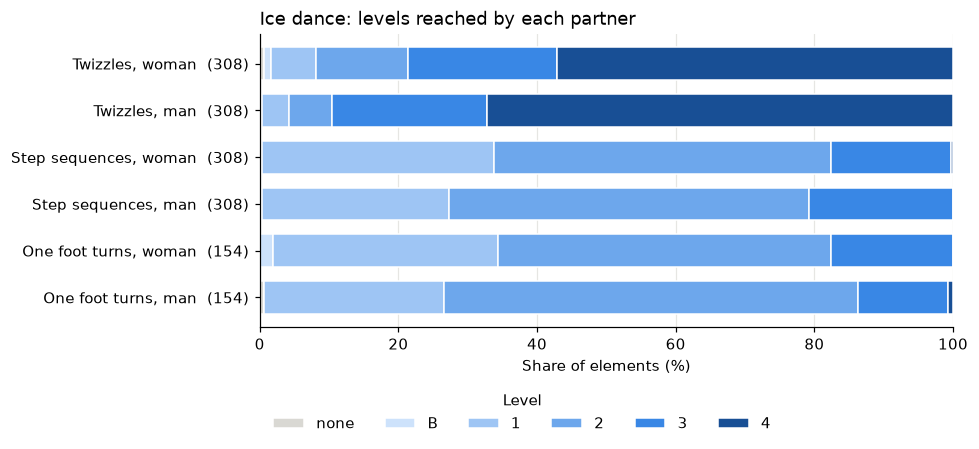

In [ ]:
# Ice dance: level reached by each partner on elements with separate levels
levels = query("""
    SELECT e.kind, e.level AS woman, e.level_partner AS man
    FROM elements e
    JOIN performances p ON e.performance_id = p.id
    JOIN segments s     ON p.segment_id = s.id
    WHERE s.category = 'ID' AND e.kind IN ('twizzles', 'step', 'turns')
""")

ORDER = ["none", "B", "1", "2", "3", "4"]
# ordinal: light (no level) to dark (level 4), one blue ramp
LEVEL_COLORS = {"none": "#d9d8d3", "B": "#cde2fb", "1": "#9ec5f4",
                "2": "#6da7ec", "3": "#3987e5", "4": "#184f95"}
KINDS = [("twizzles", "Twizzles"), ("step", "Step sequences"), ("turns", "One foot turns")]

rows = []
for kind, label in KINDS:
    d = levels[levels.kind == kind]
    for column, who in [("woman", "Woman"), ("man", "Man")]:
        shares = d[column].fillna("none").value_counts(normalize=True) * 100
        rows.append((f"{label}, {who.lower()}", [shares.get(level, 0) for level in ORDER], len(d)))

fig, ax = plt.subplots(figsize=(9, 0.45 * len(rows) + 1.6))
for y, (name, shares, n) in enumerate(rows):
    left = 0
    for level, share in zip(ORDER, shares):
        ax.barh(y, share, left=left, height=0.7, color=LEVEL_COLORS[level],
                edgecolor="white", linewidth=1, label=level if y == 0 else None)
        left += share
ax.set_yticks(range(len(rows)), [f"{name}  ({n})" for name, shares, n in rows])
ax.invert_yaxis()                      # first row at the top
ax.set_xlim(0, 100)
ax.set_xlabel("Share of elements (%)")
ax.grid(axis="y", visible=False)
ax.legend(title="Level", ncols=len(ORDER), frameon=False,
          loc="upper left", bbox_to_anchor=(0, -0.18))
ax.set_title("Ice dance: levels reached by each partner", loc="left")
fig.tight_layout()
plt.show()

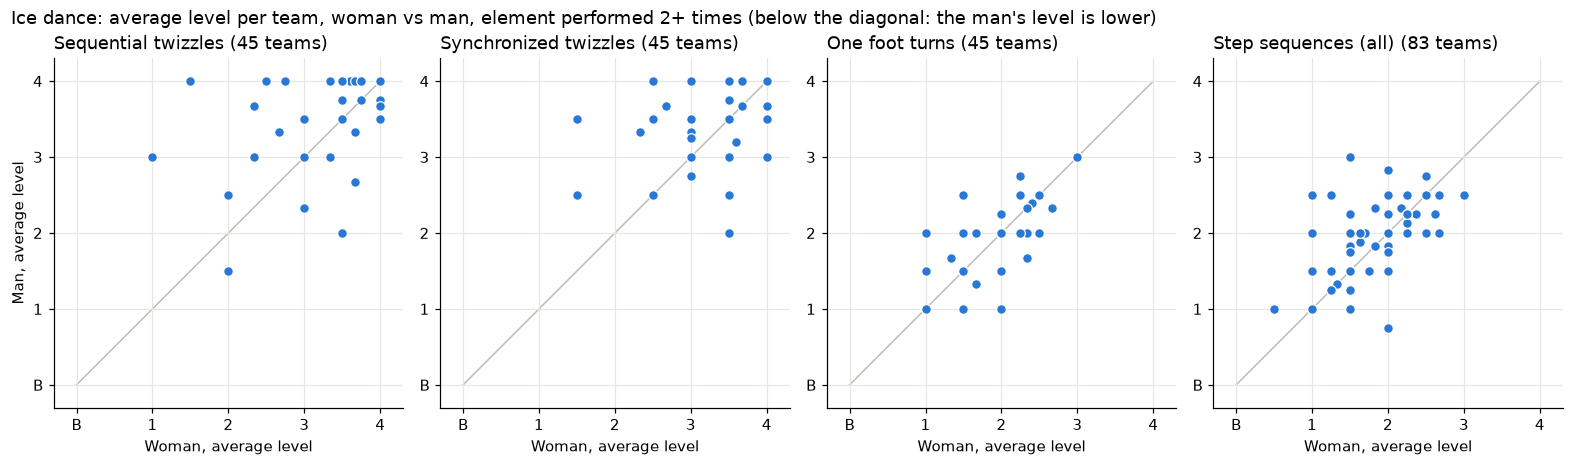

In [ ]:
# Ice dance: average level of the woman vs the man, per team, for each element type
# with separate levels. One dot = one team (skater_id + partner_id), averaged over
# all its performances, only if the team performed that element type at least twice.
# All step sequences (circular, midline, diagonal, serpentine) count as one type.
# B = 0, then 1..4; "no level" is left out of the average.
MIN_ELEMENTS = 2

team_levels = query("""
    SELECT p.skater_id, p.partner_id, e.base, e.level AS woman, e.level_partner AS man
    FROM elements e
    JOIN performances p ON e.performance_id = p.id
    JOIN segments s     ON p.segment_id = s.id
    WHERE s.category = 'ID' AND e.kind IN ('twizzles', 'step', 'turns')
""")
LEVEL_NUMBER = {"B": 0, "1": 1, "2": 2, "3": 3, "4": 4}
team_levels["woman"] = team_levels.woman.map(LEVEL_NUMBER)    # None -> NaN, left out of means
team_levels["man"] = team_levels.man.map(LEVEL_NUMBER)

# Element type: every step sequence becomes "St", the others keep their base code
STEP_SEQUENCES = {"CiSt", "MiSt", "DiSt", "SeSt"}
team_levels["type"] = team_levels.base.where(~team_levels.base.isin(STEP_SEQUENCES), "St")

averages = (team_levels
            .groupby(["type", "skater_id", "partner_id"])
            .agg(woman=("woman", "mean"), man=("man", "mean"), elements=("woman", "size"))
            .reset_index())
averages = averages[averages.elements >= MIN_ELEMENTS]        # performed twice or more

TYPES = [("SqTw", "Sequential twizzles"), ("SyTw", "Synchronized twizzles"),
         ("OFT", "One foot turns"), ("St", "Step sequences (all)")]
TYPES = [(t, name) for t, name in TYPES if (averages.type == t).any()]   # only types with teams left

fig, axes = plt.subplots(1, len(TYPES), figsize=(3.6 * len(TYPES), 4))
for ax, (element_type, name) in zip(axes, TYPES):
    d = averages[averages.type == element_type]
    ax.plot([0, 4], [0, 4], color="#bdbcb6", linewidth=1, zorder=0)   # equal levels
    ax.scatter(d.woman, d.man, s=40, color=COLORS["M"], edgecolor="white", linewidth=0.8)
    ax.set_title(f"{name} ({len(d)} teams)", loc="left")
    ax.set_xlim(-0.3, 4.3)
    ax.set_ylim(-0.3, 4.3)
    ax.set_xticks(range(5), ["B", "1", "2", "3", "4"])
    ax.set_yticks(range(5), ["B", "1", "2", "3", "4"])
    ax.set_aspect("equal")
    ax.set_xlabel("Woman, average level")
axes[0].set_ylabel("Man, average level")
fig.suptitle(f"Ice dance: average level per team, woman vs man, element performed "
             f"{MIN_ELEMENTS}+ times (below the diagonal: the man's level is lower)",
             x=0.01, ha="left")
fig.tight_layout()
plt.show()

## Jump success rate

outcome,clean,q,<,<<,e,fall,other,total
row,,,,,,,,
GrandPrixDeFrance SP,33,4,1,0,0,5,2,45
GrandPrixDeFrance FS,90,4,4,0,0,8,1,107
SkateCanadaInternational SP,32,7,1,0,0,4,2,46
SkateCanadaInternational FS,95,8,9,0,0,3,1,116
CupOfChina SP,38,4,2,1,0,1,1,47
CupOfChina FS,98,7,5,0,0,4,0,114
SkateAmerica SP,33,5,4,0,0,4,0,46
SkateAmerica FS,100,7,1,1,0,8,0,117
FinlandiaTrophy SP,36,2,1,1,0,6,2,48


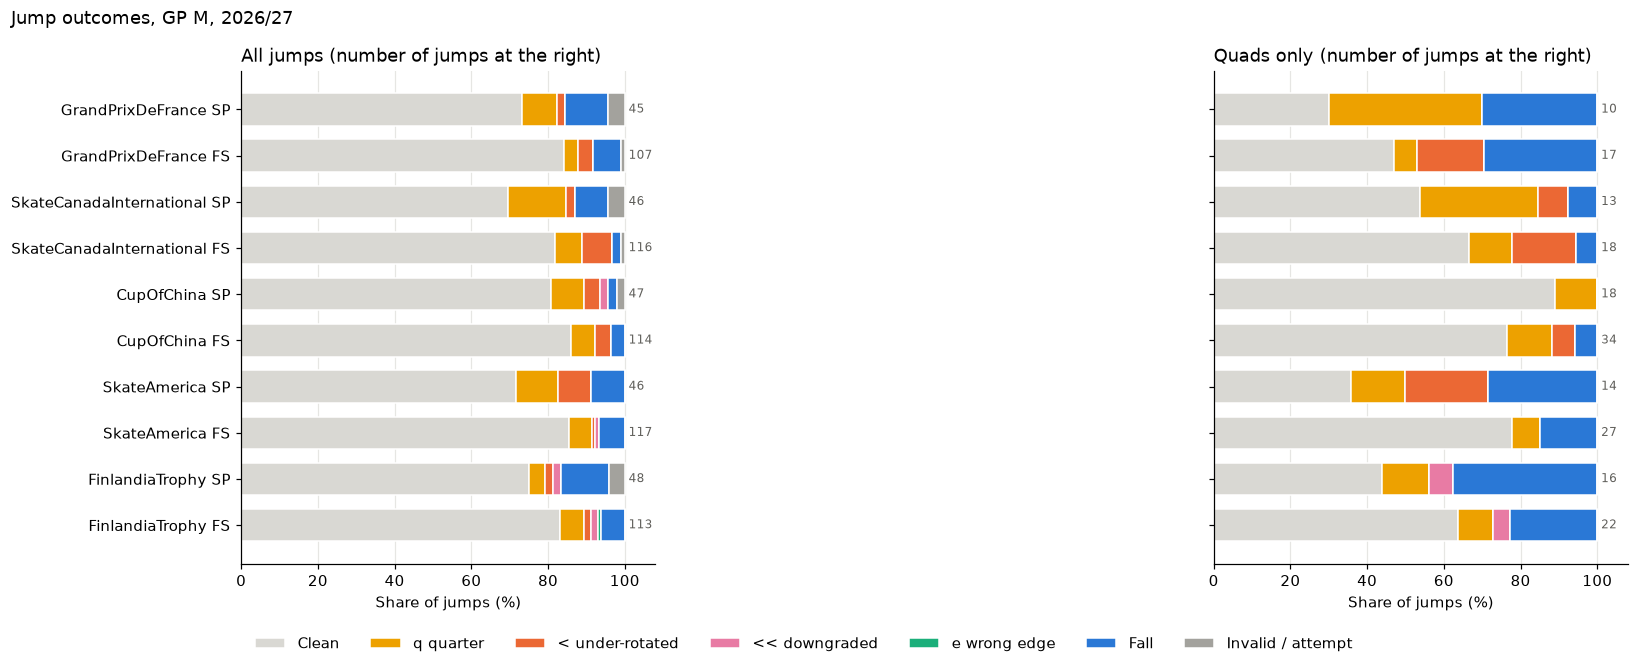

In [20]:
# Jump outcomes per event and segment: clean, rotation and edge calls, falls.
# Each jump (each part of a combination) gets one outcome, the most serious one:
#   fall (F / Fx on its element: the protocol doesn't say which jump of a combination fell)
#   > other (invalid * or attempt) > << > < > q > e > clean.
# "!" counts as clean (it doesn't lower the base value). A popped jump (a planned 3A
# done as 1A) looks like a clean single in the protocol.
SERIES, CATEGORY = "GP", "M"          # change to "CS" / "W", "P"... for other groups

jumps = query(f"""
    SELECT c.event_code, c.start_date, s.segment, ep.rotations >= 4 AS quad,
           CASE WHEN e.fall = 1                          THEN 'fall'
                WHEN ep.invalid = 1 OR ep.rotations = 0 THEN 'other'
                WHEN ep.downgraded = 1                  THEN '<<'
                WHEN ep.under_rotated = 1               THEN '<'
                WHEN ep.quarter = 1                     THEN 'q'
                WHEN ep.wrong_edge = 1                  THEN 'e'
                ELSE 'clean' END AS outcome
    FROM element_parts ep
    JOIN elements e     ON ep.element_id = e.id
    JOIN performances p ON e.performance_id = p.id
    JOIN segments s     ON p.segment_id = s.id
    JOIN competitions c ON s.competition_id = c.id
    WHERE c.series = '{SERIES}' AND s.category = '{CATEGORY}'
    ORDER BY c.start_date, s.segment DESC
""")
OUTCOMES = [("clean", "Clean", "#d9d8d3"), ("q", "q quarter", "#eda100"),
            ("<", "< under-rotated", "#eb6834"), ("<<", "<< downgraded", "#e87ba4"),
            ("e", "e wrong edge", "#1baf7a"), ("fall", "Fall", "#2a78d6"),
            ("other", "Invalid / attempt", "#a3a29d")]

jumps["row"] = jumps.event_code + " " + jumps.segment
rows = list(dict.fromkeys(jumps.row))                  # date order, SP before FS
counts = pd.crosstab(jumps.row, jumps.outcome).reindex(index=rows,
                                                        columns=[o for o, _, _ in OUTCOMES], fill_value=0)
display(counts.assign(total=counts.sum(axis=1)))

fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(rows) + 2), sharey=True)
for ax, (title, subset) in zip(axes, [("All jumps", jumps), ("Quads only", jumps[jumps.quad == 1])]):
    shares = (pd.crosstab(subset.row, subset.outcome, normalize="index") * 100).reindex(
        index=rows, columns=[o for o, _, _ in OUTCOMES], fill_value=0)
    totals = subset.row.value_counts().reindex(rows, fill_value=0)
    left = pd.Series(0.0, index=rows)
    for code, label, color in OUTCOMES:
        ax.barh(rows, shares[code], left=left, color=color, edgecolor="white",
                linewidth=1, height=0.7, label=label)
        left += shares[code]
    for y, n in enumerate(totals):                        # number of jumps at the end of each bar
        ax.text(101, y, f"{n}", va="center", fontsize=8, color="#5f5e5a")
    ax.set_xlim(0, 108)
    ax.set_xlabel("Share of jumps (%)")
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{title} (number of jumps at the right)", loc="left")
axes[0].invert_yaxis()
axes[0].legend(ncols=len(OUTCOMES), frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12))
fig.suptitle(f"Jump outcomes, {SERIES} {CATEGORY}, 2026/27", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## Lutz and flip edges

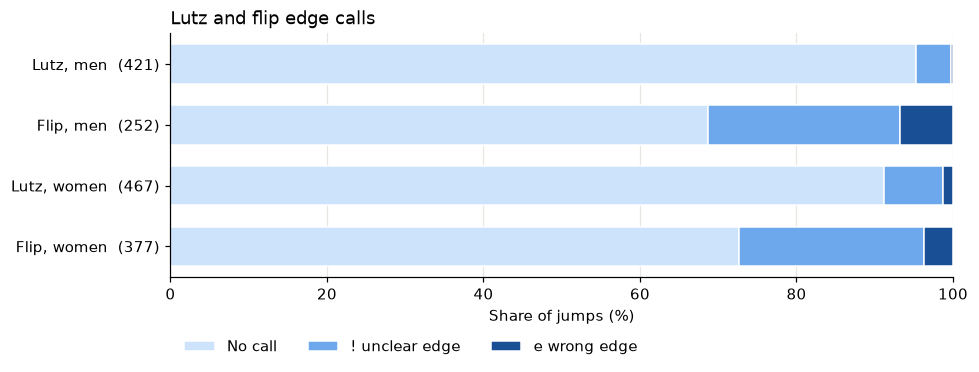

,skater,category,jump,jumps,e_calls,unclear_calls,call_rate
0,Lotta ARTIMO,W,F,6,2,4,100.0
1,Inga GURGENIDZE,W,F,6,3,3,100.0
2,Raffaele Francesco ZICH,M,F,4,1,3,100.0
3,Yuseong KIM,W,Lz,9,1,7,89.0
4,Ahsun YUN,W,F,6,0,5,83.0
5,Seoyoung KIM,W,F,6,0,5,83.0
6,Nikita KRIVOSHEYEV,M,F,6,4,1,83.0
7,Arlet LEVANDI,M,F,5,2,2,80.0
8,Yujae KIM,W,F,4,1,2,75.0
9,Fee Ann LANDRY,W,F,6,0,4,67.0


In [ ]:
# Lutz and flip edges: no call / "!" (unclear edge) / "e" (wrong edge), every Lutz and
# flip including those in combinations, men and women (pairs: too few side-by-side ones)
edges = query("""
    SELECT s.category, ep.jump,
           SUM(ep.wrong_edge = 0 AND ep.unclear_edge = 0) AS no_call,
           SUM(ep.unclear_edge = 1)                       AS unclear,
           SUM(ep.wrong_edge = 1)                         AS wrong,
           COUNT(*)                                       AS total
    FROM element_parts ep
    JOIN elements e     ON ep.element_id = e.id
    JOIN performances p ON e.performance_id = p.id
    JOIN segments s     ON p.segment_id = s.id
    WHERE ep.jump IN ('Lz', 'F') AND ep.rotations > 0 AND s.category IN ('M', 'W')
    GROUP BY s.category, ep.jump
    ORDER BY s.category, ep.jump DESC
""")
JUMP_NAMES = {"Lz": "Lutz", "F": "Flip"}
CATEGORY_NAMES = {"M": "men", "W": "women"}
# ordinal: light = no call, darker = more serious call
EDGES = [("no_call", "No call", "#cde2fb"), ("unclear", "! unclear edge", "#6da7ec"),
         ("wrong", "e wrong edge", "#184f95")]

labels = [f"{JUMP_NAMES[j]}, {CATEGORY_NAMES[c]}  ({t})"
          for c, j, t in zip(edges.category, edges.jump, edges.total)]
fig, ax = plt.subplots(figsize=(9, 0.5 * len(edges) + 1.6))
left = pd.Series(0.0, index=edges.index)
for column, label, color in EDGES:
    share = 100 * edges[column] / edges.total
    ax.barh(labels, share, left=left, color=color, edgecolor="white", linewidth=1,
            height=0.65, label=label)
    left += share
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of jumps (%)")
ax.grid(axis="y", visible=False)
ax.legend(ncols=3, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.2))
ax.set_title("Lutz and flip edge calls", loc="left")
fig.tight_layout()
plt.show()

# Skaters with repeated edge calls (at least 4 Lutzes or flips of that type)
repeated = query("""
    SELECT sk.first_name || ' ' || sk.last_name AS skater, s.category, ep.jump,
           COUNT(*)              AS jumps,
           SUM(ep.wrong_edge)    AS e_calls,
           SUM(ep.unclear_edge)  AS unclear_calls,
           ROUND(100.0 * (SUM(ep.wrong_edge) + SUM(ep.unclear_edge)) / COUNT(*)) AS call_rate
    FROM element_parts ep
    JOIN elements e     ON ep.element_id = e.id
    JOIN performances p ON e.performance_id = p.id
    JOIN segments s     ON p.segment_id = s.id
    JOIN skaters sk     ON p.skater_id = sk.id
    WHERE ep.jump IN ('Lz', 'F') AND ep.rotations > 0 AND s.category IN ('M', 'W')
    GROUP BY sk.id, ep.jump
    HAVING COUNT(*) >= 4 AND SUM(ep.wrong_edge) + SUM(ep.unclear_edge) >= 2
    ORDER BY call_rate DESC, jumps DESC
""")
display(repeated.head(20))

## Points lost to calls

571 called jumps, 924.8 base value points lost (0 jumps not found in the Scale of Values)


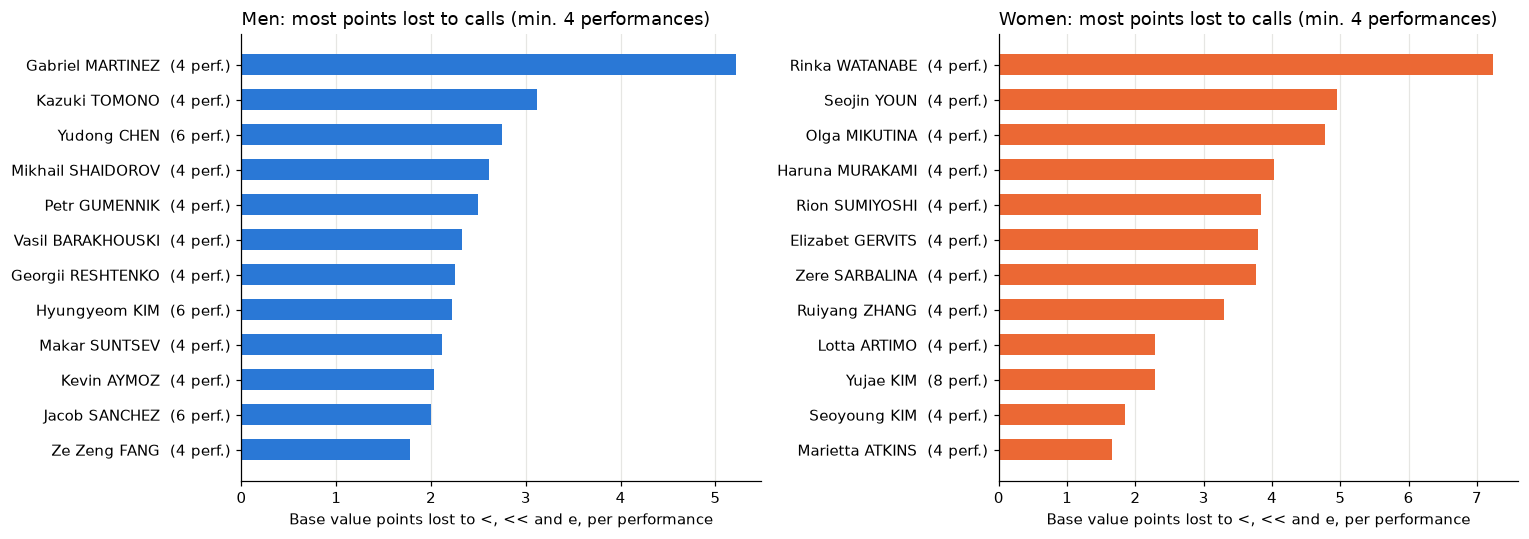

In [ ]:
# Points lost to calls: for every jump called <, << or e, the Scale of Values value of the
# clean jump minus the value of the called jump (with the x bonus and +REP/RFE applied).
# q and ! don't lower the base value (their cost is in the GOE, not counted here).
MIN_PERFORMANCES = 4

called = query("""
    SELECT c.season, s.category, p.skater_id,
           sk.first_name || ' ' || sk.last_name AS skater,
           ep.rotations, ep.jump, ep.markers, e.second_half, e.flags AS element_flags
    FROM element_parts ep
    JOIN elements e     ON ep.element_id = e.id
    JOIN performances p ON e.performance_id = p.id
    JOIN segments s     ON p.segment_id = s.id
    JOIN competitions c ON s.competition_id = c.id
    JOIN skaters sk     ON p.skater_id = sk.id
    WHERE s.category IN ('M', 'W') AND ep.rotations > 0 AND ep.invalid = 0
      AND (ep.under_rotated = 1 OR ep.downgraded = 1 OR ep.wrong_edge = 1)
""")
scale = query("SELECT season, code, base_value FROM scale_of_values WHERE discipline = 'SinglesPairs'")
value = {(row.season, row.code): row.base_value for row in scale.itertuples()}


def points_lost(row):
    """Clean value - called value of one jump, from the Scale of Values."""
    signs = "".join(ch for ch in row.markers if ch in "<qe!")
    stem = "Eu" if row.jump == "Eu" else f"{row.rotations}{row.jump}"
    clean, as_called = value.get((row.season, stem)), value.get((row.season, stem + signs))
    if clean is None or as_called is None:
        return None
    factor = 1.1 if row.second_half else 1.0
    if "REP" in row.element_flags or "RFE" in row.element_flags:
        factor *= 0.8
    return (clean - as_called) * factor


called["lost"] = called.apply(points_lost, axis=1)
print(f"{len(called)} called jumps, {called.lost.sum():.1f} base value points lost "
      f"({called.lost.isna().sum()} jumps not found in the Scale of Values)")

# per skater: total lost, and per performance (all their performances count, called or not)
performances = query("""
    SELECT p.skater_id, s.category, COUNT(*) AS performances
    FROM performances p JOIN segments s ON p.segment_id = s.id
    WHERE s.category IN ('M', 'W')
    GROUP BY p.skater_id, s.category
""")
per_skater = (called.groupby(["skater_id", "skater", "category"])
              .agg(calls=("lost", "size"), lost=("lost", "sum")).reset_index()
              .merge(performances, on=["skater_id", "category"]))
per_skater["lost_per_performance"] = per_skater.lost / per_skater.performances
per_skater = per_skater[per_skater.performances >= MIN_PERFORMANCES]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (category, title) in zip(axes, [("M", "Men"), ("W", "Women")]):
    top = (per_skater[per_skater.category == category]
           .sort_values("lost_per_performance", ascending=False).head(12))
    labels = [f"{name}  ({n} perf.)" for name, n in zip(top.skater, top.performances)]
    ax.barh(labels, top.lost_per_performance, color=COLORS[category], height=0.6)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Base value points lost to <, << and e, per performance")
    ax.set_title(f"{title}: most points lost to calls (min. {MIN_PERFORMANCES} performances)",
                 loc="left")
fig.tight_layout()
plt.show()

## Spin level 4 rate

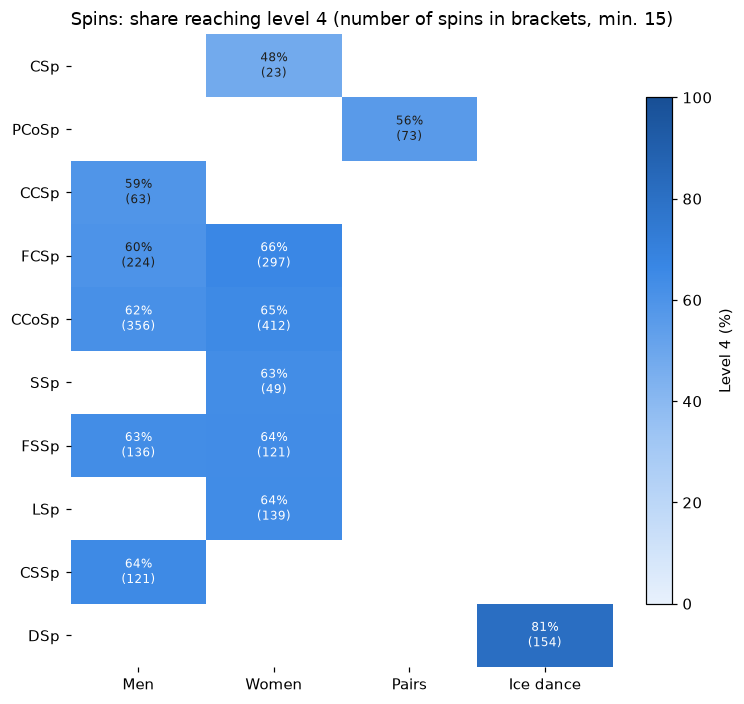

In [ ]:
# Spin level 4 rate by spin type and discipline (spin types with at least 15 spins)
from matplotlib.colors import LinearSegmentedColormap

MIN_SPINS = 15
spins = query(f"""
    SELECT s.category, e.base, COUNT(*) AS spins, SUM(e.level = '4') AS level4
    FROM elements e
    JOIN performances p ON e.performance_id = p.id
    JOIN segments s     ON p.segment_id = s.id
    WHERE e.kind = 'spin'
    GROUP BY s.category, e.base
    HAVING COUNT(*) >= {MIN_SPINS}
""")
spins["rate"] = 100 * spins.level4 / spins.spins
rate = spins.pivot(index="base", columns="category", values="rate")
count = spins.pivot(index="base", columns="category", values="spins")
order = [c for c in ["M", "W", "P", "ID"] if c in rate.columns]
rate, count = rate[order], count[order]
rate = rate.loc[rate.mean(axis=1).sort_values().index]          # hardest spin type at the top
count = count.loc[rate.index]

# one blue ramp, light = low rate, dark = high rate
BLUES = LinearSegmentedColormap.from_list("blues", ["#e8f1fc", "#9ec5f4", "#3987e5", "#184f95"])
fig, ax = plt.subplots(figsize=(7, 0.5 * len(rate) + 1.5))
image = ax.imshow(rate.values, cmap=BLUES, vmin=0, vmax=100, aspect="auto")
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        value = rate.values[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.0f}%\n({count.values[i, j]:.0f})", ha="center", va="center",
                    fontsize=8, color="white" if value > 60 else "#1f1f1d")
ax.set_xticks(range(len(order)), [{"M": "Men", "W": "Women", "P": "Pairs", "ID": "Ice dance"}[c]
                                  for c in order])
ax.set_yticks(range(len(rate)), rate.index)
ax.grid(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
fig.colorbar(image, ax=ax, label="Level 4 (%)", shrink=0.8)
ax.set_title(f"Spins: share reaching level 4 (number of spins in brackets, min. {MIN_SPINS})",
             loc="left")
fig.tight_layout()
plt.show()

## Pattern dance key points

result,N,T,X,Y
position,,,,
1,53.0,1.0,1.0,45.0
2,53.0,3.0,0.0,44.0
3,79.0,0.0,0.0,21.0
4,63.0,0.0,0.0,37.0


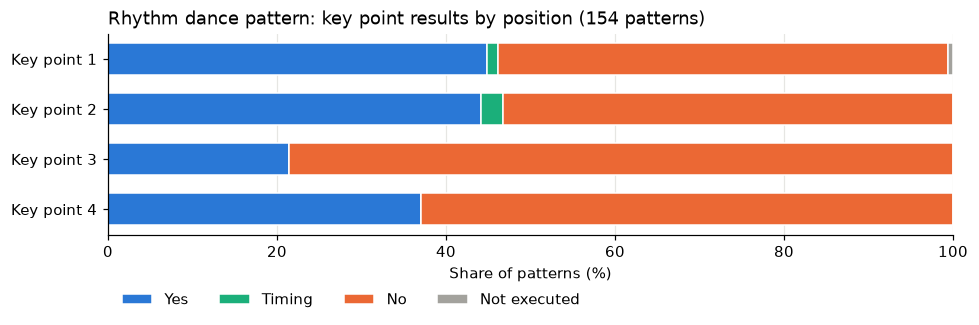

In [ ]:
# Rhythm dance pattern: result of each key point position (1st, 2nd, 3rd, 4th)
# Y = yes, N = no, T = timing, X = not executed (ISU abbreviations)
patterns = query("""
    SELECT e.key_points
    FROM elements e
    WHERE e.kind = 'pattern' AND e.key_points IS NOT NULL
""")
rows = [(position, result)
        for key_points in patterns.key_points
        for position, result in enumerate(key_points, start=1)]
key_points = pd.DataFrame(rows, columns=["position", "result"])
shares = pd.crosstab(key_points.position, key_points.result, normalize="index") * 100
display(shares.round(0))

RESULTS = [("Y", "Yes", "#2a78d6"), ("T", "Timing", "#1baf7a"),
           ("N", "No", "#eb6834"), ("X", "Not executed", "#a3a29d")]
fig, ax = plt.subplots(figsize=(9, 3.2))
left = pd.Series(0.0, index=shares.index)
for code, label, color in RESULTS:
    if code not in shares:
        continue
    ax.barh([f"Key point {p}" for p in shares.index], shares[code], left=left,
            color=color, edgecolor="white", linewidth=1, height=0.65, label=label)
    left += shares[code]
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of patterns (%)")
ax.grid(axis="y", visible=False)
ax.legend(ncols=4, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.22))
ax.set_title(f"Rhythm dance pattern: key point results by position ({len(patterns)} patterns)", loc="left")
fig.tight_layout()
plt.show()

## What if clean

,clean_rank,rank,rank_change,skater,nation,total,call_points,falls,clean_total
0,1,1,0,Adam SIAO HIM FA,FRA,181.78,0.00,0,181.78
1,2,2,0,Kao MIURA,JPN,175.29,0.00,1,176.29
2,3,3,0,Minkyu SEO,KOR,161.07,0.00,1,162.07
3,4,4,0,Sota YAMAMOTO,JPN,147.22,0.00,0,147.22
5,5,6,1,Jimmy MA,USA,144.33,1.76,0,146.09
4,6,5,-1,Aleksandr SELEVKO,EST,144.49,0.00,0,144.49
6,7,7,0,Francois PITOT,FRA,141.77,0.00,2,143.77
7,8,8,0,Nikolaj MEMOLA,ITA,140.91,0.00,0,140.91
10,9,11,2,Mikhail SHAIDOROV,KAZ,126.30,8.16,2,136.46
8,10,9,-1,Jacob SANCHEZ,USA,132.97,1.94,1,135.91


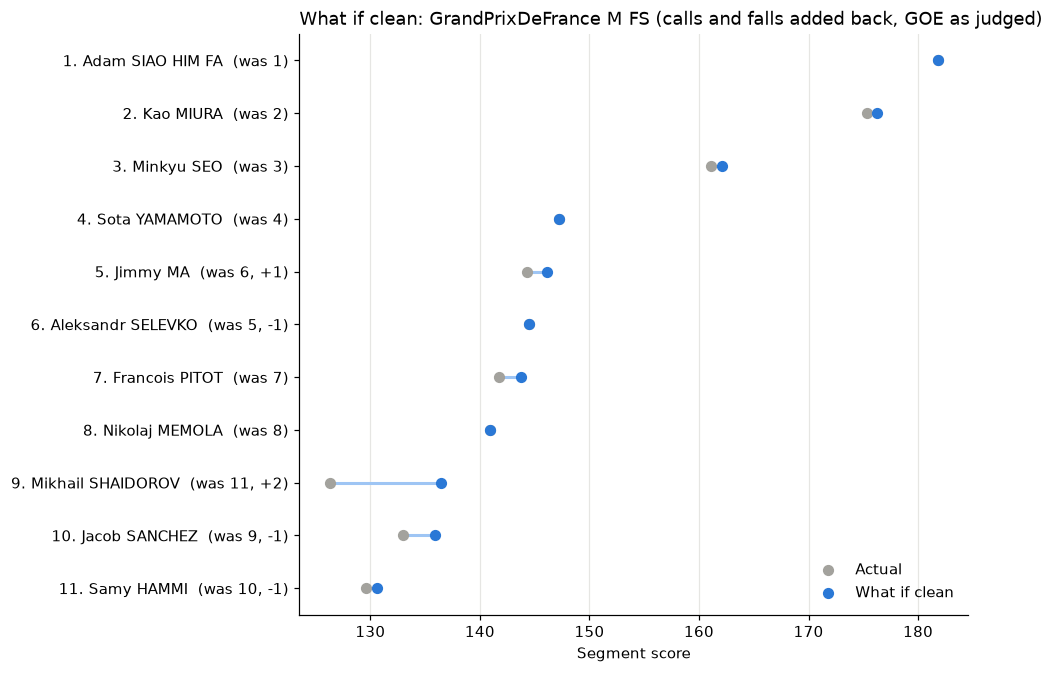

In [21]:
# "What if clean" ranking of one segment.
# Adds back the base value lost to <, << and e calls: each called jump is valued as its
# clean version in the Scale of Values (x bonus and +REP/RFE applied as usual).
# The GOE stays as judged, so this is an indication, not a real score.
# Optionally adds back the fall deductions, exactly as printed on the protocol's
# deduction line (other deductions, e.g. time violations, stay deducted).
# Invalid jumps (*) and attempts stay as they are; q and ! don't change the base value.
# In pairs, only side-by-side jumps are adjusted (not throws or twists).
EVENT, CATEGORY, SEGMENT = "GrandPrixDeFrance", "M", "FS"
ADD_BACK_FALLS = True

segment_filter = (f"c.event_code = '{EVENT}' AND s.category = '{CATEGORY}' "
                  f"AND s.segment = '{SEGMENT}'")
results = query(f"""
    SELECT p.id AS performance_id, p.rank, p.total,
           sk.first_name || ' ' || sk.last_name
             || COALESCE(' / ' || pa.first_name || ' ' || pa.last_name, '') AS skater,
           p.nation,
           (SELECT COALESCE(SUM(d.count), 0) FROM deductions d
            WHERE d.performance_id = p.id AND d.type = 'Falls')          AS falls,
           (SELECT COALESCE(-SUM(d.points), 0) FROM deductions d
            WHERE d.performance_id = p.id AND d.type = 'Falls')          AS fall_deduction
    FROM performances p
    JOIN segments s       ON p.segment_id = s.id
    JOIN competitions c   ON s.competition_id = c.id
    JOIN skaters sk       ON p.skater_id = sk.id
    LEFT JOIN skaters pa  ON p.partner_id = pa.id
    WHERE {segment_filter}
""")
called = query(f"""
    SELECT p.id AS performance_id, c.season, ep.rotations, ep.jump, ep.markers,
           e.second_half, e.flags AS element_flags
    FROM element_parts ep
    JOIN elements e     ON ep.element_id = e.id
    JOIN performances p ON e.performance_id = p.id
    JOIN segments s     ON p.segment_id = s.id
    JOIN competitions c ON s.competition_id = c.id
    WHERE {segment_filter} AND ep.rotations > 0 AND ep.invalid = 0
      AND (ep.under_rotated = 1 OR ep.downgraded = 1 OR ep.wrong_edge = 1)
""")
scale = query("SELECT season, code, base_value FROM scale_of_values WHERE discipline = 'SinglesPairs'")
value = {(row.season, row.code): row.base_value for row in scale.itertuples()}


def points_regained(row):
    """Clean value - called value of one jump, from the Scale of Values."""
    signs = "".join(ch for ch in row.markers if ch in "<qe!")
    stem = "Eu" if row.jump == "Eu" else f"{row.rotations}{row.jump}"
    factor = 1.1 if row.second_half else 1.0
    if "REP" in row.element_flags or "RFE" in row.element_flags:
        factor *= 0.8
    return (value[(row.season, stem)] - value[(row.season, stem + signs)]) * factor


called["regained"] = called.apply(points_regained, axis=1) if len(called) else []
results = results.merge(called.groupby("performance_id").regained.sum().rename("call_points"),
                        on="performance_id", how="left").fillna({"call_points": 0})
results["fall_points"] = results.fall_deduction if ADD_BACK_FALLS else 0
results["clean_total"] = results.total + results.call_points + results.fall_points
results["clean_rank"] = results.clean_total.rank(ascending=False, method="min").astype(int)
results["rank_change"] = results["rank"] - results.clean_rank       # + = moves up
results = results.sort_values("clean_rank")
display(results[["clean_rank", "rank", "rank_change", "skater", "nation", "total",
                 "call_points", "falls", "fall_points", "clean_total"]].round(2))

# Chart: actual total (grey) -> what-if-clean total (blue), sorted by what-if rank
fig, ax = plt.subplots(figsize=(9, 0.42 * len(results) + 1.6))
y = range(len(results))
ax.hlines(y, results.total, results.clean_total, color="#9ec5f4", linewidth=2, zorder=1)
ax.scatter(results.total, y, s=40, color="#a3a29d", zorder=2, label="Actual")
ax.scatter(results.clean_total, y, s=40, color="#2a78d6", zorder=3, label="What if clean")
labels = [f"{cr}. {name}  (was {r}{', ' + format(c, '+d') if c else ''})"
          for cr, name, r, c in zip(results.clean_rank, results.skater, results["rank"],
                                    results.rank_change)]
ax.set_yticks(list(y), labels)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Segment score")
ax.legend(frameon=False, loc="lower right")
falls_note = " and falls" if ADD_BACK_FALLS else ""
ax.set_title(f"What if clean: {EVENT} {CATEGORY} {SEGMENT} (calls{falls_note} added back, GOE as judged)",
             loc="left")
fig.tight_layout()
plt.show()